In [7]:

import os
from pathlib import Path
import spiceypy as spice
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from mpl_toolkits.mplot3d import Axes3D



import re

In [ ]:
import spiceypy as spice
print(spice.tkvrsn('TOOLKIT'))

CSPICE_N0067


In [13]:
# list the files under spice/extras/mk
print("Files under spice/extras/mk:")
for file in (base / "extras" / "mk").iterdir():
    print(file.name)

Files under spice/extras/mk:
cas_2011_v05.tm
cas_2008_v03.tm
cas_2006_v02.tm
cas_2001_v04.tm
cas_2016_v03.tm
cas_1998_v18.tm
cas_2003_v05.tm
cas_1997_v01.tm
cas_2014_v02.tm
cas_2013_v04.tm
cas_2004_v03.tm
cas_2004_v13.tm
cas_2003_v21.tm
cas_2004_v27.tm
cas_1997_v11.tm
cas_1998_v08.tm
cas_2003_v15.tm
cas_1999_v10.tm
cas_2006_v26.tm
cas_2001_v14.tm
cas_2006_v12.tm
cas_2008_v13.tm
cas_2011_v15.tm
cas_2001_v20.tm
cas_2000_v18.tm
mkinfo.txt
cas_2016_v07.tm
cas_2010_v19.tm
cas_2011_v01.tm
cas_2008_v07.tm
cas_2006_v06.tm
cas_2004_v07.tm
cas_2003_v01.tm
cas_1999_v04.tm
cas_2002_v19.tm
cas_1997_v05.tm
cas_2014_v06.tm
cas_2004_v23.tm
cas_1997_v15.tm
cas_1999_v14.tm
cas_2003_v11.tm
cas_2002_v09.tm
cas_2004_v17.tm
cas_2013_v10.tm
cas_2003_v25.tm
cas_1999_v20.tm
cas_2012_v08.tm
cas_1997_v21.tm
cas_2006_v16.tm
cas_2008_v17.tm
cas_2010_v09.tm
cas_2011_v11.tm
cas_2001_v24.tm
cas_2008_v23.tm
cas_2006_v22.tm
cas_2000_v08.tm
cas_2001_v10.tm
cas_2001_v01.tm
cas_2000_v19.tm
cas_2016_v06.tm
cas_2010_v18.tm


In [11]:
base

PosixPath('/Users/chengzhimao/Documents/Code/saturn2025/data/spice')

In [20]:
import os
from pathlib import Path
import spiceypy as spice

spice.kclear()

spice_root = Path("/Users/chengzhimao/Documents/Code/saturn2025/data/spice")
mk = spice_root / "extras" / "mk" / "cas_2004_v27.tm"

old_cwd = Path.cwd()
os.chdir(spice_root)

try:
    spice.furnsh(str(mk))
finally:
    os.chdir(old_cwd)

print("Loaded kernels:", spice.ktotal("ALL"))

Loaded kernels: 151


In [21]:
saturn_radii = spice.bodvrd("SATURN", "RADII", 3)[1]
RS_km = saturn_radii[0]

In [ ]:
RS_km
# Saturn radius in km: 60268.0

np.float64(60268.0)

In [27]:
import os
from pathlib import Path
import spiceypy as spice
import numpy as np

spice.kclear()

spice_root = Path("/Users/chengzhimao/Documents/Code/saturn2025/data/spice")
mk = spice_root / "extras" / "mk" / "cas_2004_v27.tm"

# Stay in spice_root while using the kernels
os.chdir(spice_root)

spice.furnsh(str(mk))

print("Current folder:", Path.cwd())
print("Loaded kernels:", spice.ktotal("ALL"))

utc = "2004-07-01T00:00:00"
et = spice.utc2et(utc)

state, light_time = spice.spkezr(
    "CASSINI",
    et,
    "J2000",
    "NONE",
    "SATURN"
)

position_km = state[:3]
velocity_km_s = state[3:]
speed_km_s = np.linalg.norm(velocity_km_s)

print("Position relative to Saturn [km]:", position_km)
print("Velocity relative to Saturn [km/s]:", velocity_km_s)
print("Speed relative to Saturn [km/s]:", speed_km_s)

Current folder: /Users/chengzhimao/Documents/Code/saturn2025/data/spice
Loaded kernels: 151
Position relative to Saturn [km]: [ 2.20890409e+04 -2.01675730e+05 -1.03675690e+02]
Velocity relative to Saturn [km/s]: [10.36254086 16.96313393  2.47380257]
Speed relative to Saturn [km/s]: 20.031222254182556


In [29]:
import pandas as pd
import numpy as np

start_utc = "2004-01-01T00:00:00"
stop_utc  = "2004-01-03T00:00:00"   # test with 2 days first

start_et = spice.utc2et(start_utc)
stop_et = spice.utc2et(stop_utc)

step_seconds = 3600  # 1 hour
ets = np.arange(start_et, stop_et + step_seconds, step_seconds)

rows = []

for et_i in ets:
    utc_i = spice.et2utc(et_i, "ISOC", 3)

    state, lt = spice.spkezr(
        "CASSINI",
        et_i,
        "CASSINI_KRTP",
        "NONE",
        "SATURN"
    )

    rtp_pos = state[:3]
    rtp_vel = state[3:]

    rows.append({
        "utc": utc_i,
        "R_km": rtp_pos[0],
        "Theta_km": rtp_pos[1],
        "Phi_km": rtp_pos[2],
        "vR_km_s": rtp_vel[0],
        "vTheta_km_s": rtp_vel[1],
        "vPhi_km_s": rtp_vel[2],
        "speed_km_s": np.linalg.norm(rtp_vel),
    })

df = pd.DataFrame(rows)
df.head()

,utc,R_km,Theta_km,Phi_km,vR_km_s,vTheta_km_s,vPhi_km_s,speed_km_s
0,2004-01-01T00:00:00.000,8.741564e+07,-1.962808e-10,7.013147e-09,-5.294363,-5.185936e-17,4.062406e-16,5.294363
1,2004-01-01T01:00:00.000,8.739658e+07,3.079343e-10,-3.960498e-09,-5.294377,-7.964847e-17,6.580076e-18,5.294377
2,2004-01-01T02:00:00.000,8.737752e+07,2.270709e-09,4.741055e-09,-5.294390,1.464902e-16,-1.260793e-16,5.294390
3,2004-01-01T03:00:00.000,8.735846e+07,4.661763e-10,9.552612e-10,-5.294403,2.271563e-16,-1.205228e-16,5.294403
4,2004-01-01T04:00:00.000,8.733940e+07,-1.233572e-09,5.021859e-09,-5.294415,1.632775e-16,-2.905637e-16,5.294415


In [30]:
state

array([ 8.64816861e+07, -6.59358237e-10,  4.41942046e-09, -5.29459241e+00,
       -8.73658174e-17,  9.96710666e-17])

# Load in spice

In [3]:
def latest_tm_for_year(year):
    files = list(mk_dir.glob(f"cas_{year}_v*.tm"))

    if not files:
        raise FileNotFoundError(f"No meta-kernel found for year {year}")

    def version_number(path):
        m = re.search(r"_v(\d+)\.tm$", path.name)
        return int(m.group(1))

    return max(files, key=version_number)


def load_cassini_year(year):
    spice.kclear()

    mk = latest_tm_for_year(year)
    spice.furnsh(str(mk))

    print(f"Loaded {mk.name}; kernels loaded = {spice.ktotal('ALL')}")

    return mk

## KRTP

In [ ]:
# Paths
spice_root = Path("/Users/chengzhimao/Documents/Code/saturn2025/data/spice")
mk_dir = spice_root / "extras" / "mk"

out_file = Path("/Users/chengzhimao/Documents/Code/saturn2025/cassini_krtp_2004_2017_60s.pkl")

# Important: stay in spice_root because the Cassini .tm files use relative paths like ./data/spk/...
os.chdir(spice_root)

print("Working directory:", Path.cwd())

In [30]:
def generate_one_year_krtp(year, step_seconds=60):
    load_cassini_year(year)

    start_utc = f"{year}-01-01T00:00:00"

    if year < 2017:
        stop_utc = f"{year + 1}-01-01T00:00:00"
    else:
        # Conservative stop before final Cassini coverage problem
        stop_utc = "2017-09-15T10:40:00"

    print(f"Generating {year}: {start_utc} to {stop_utc}")

    utc_times = pd.date_range(
        start=start_utc,
        end=stop_utc,
        freq=f"{step_seconds}s",
        inclusive="left",
        tz="UTC"
    )

    utc_strings = utc_times.strftime("%Y-%m-%dT%H:%M:%S").to_numpy()
    ets = np.array([spice.utc2et(t) for t in utc_strings], dtype=np.float64)

    states, light_times = spice.spkezr(
        "CASSINI",
        ets,
        "CASSINI_KRTP",
        "NONE",
        "SATURN"
    )

    states = np.asarray(states, dtype=np.float64)

    df = pd.DataFrame({
        "utc": utc_times,
        "et": ets,
        "R_km": states[:, 0],
        "Theta_km": states[:, 1],
        "Phi_km": states[:, 2],
        "vR_km_s": states[:, 3],
        "vTheta_km_s": states[:, 4],
        "vPhi_km_s": states[:, 5],
    })

    df["speed_km_s"] = np.linalg.norm(states[:, 3:6], axis=1)

    return df

In [42]:
step_seconds = 60

dfs = []

for year in range(2004, 2018):
    df_year = generate_one_year_krtp(year, step_seconds=step_seconds)
    print(f"{year}: rows = {len(df_year):,}")
    dfs.append(df_year)

df_all = pd.concat(dfs, ignore_index=True)

df_all.attrs["target"] = "CASSINI"
df_all.attrs["observer"] = "SATURN"
df_all.attrs["frame"] = "CASSINI_KRTP"
df_all.attrs["abcorr"] = "NONE"
df_all.attrs["step_seconds"] = step_seconds
df_all.attrs["start_utc"] = "2004-01-01T00:00:00"
df_all.attrs["stop_utc"] = "2017-09-16T00:00:00"

print("Total rows:", len(df_all))
print(df_all.head())
print(df_all.tail())

Loaded cas_2004_v27.tm; kernels loaded = 151
Generating 2004: 2004-01-01T00:00:00 to 2005-01-01T00:00:00
2004: rows = 527,040
Loaded cas_2005_v28.tm; kernels loaded = 151
Generating 2005: 2005-01-01T00:00:00 to 2006-01-01T00:00:00
2005: rows = 525,600
Loaded cas_2006_v27.tm; kernels loaded = 149
Generating 2006: 2006-01-01T00:00:00 to 2007-01-01T00:00:00
2006: rows = 525,600
Loaded cas_2007_v25.tm; kernels loaded = 162
Generating 2007: 2007-01-01T00:00:00 to 2008-01-01T00:00:00
2007: rows = 525,600
Loaded cas_2008_v23.tm; kernels loaded = 148
Generating 2008: 2008-01-01T00:00:00 to 2009-01-01T00:00:00
2008: rows = 527,040
Loaded cas_2009_v20.tm; kernels loaded = 161
Generating 2009: 2009-01-01T00:00:00 to 2010-01-01T00:00:00
2009: rows = 525,600
Loaded cas_2010_v19.tm; kernels loaded = 149
Generating 2010: 2010-01-01T00:00:00 to 2011-01-01T00:00:00
2010: rows = 525,600
Loaded cas_2011_v18.tm; kernels loaded = 144
Generating 2011: 2011-01-01T00:00:00 to 2012-01-01T00:00:00
2011: rows = 

In [43]:
df_all.to_pickle(out_file, protocol=5)

size_gb = out_file.stat().st_size / 1024**3
print("Saved:", out_file)
print(f"File size: {size_gb:.3f} GB")

Saved: /Users/chengzhimao/Documents/Code/saturn2025/cassini_krtp_2004_2017_60s.pkl
File size: 0.483 GB


## J2000

In [4]:
# Main paths
spice_root = Path("/Users/chengzhimao/Documents/Code/saturn2025/data/spice")
mk_dir = spice_root / "extras" / "mk"

out_file = Path(
    "/Users/chengzhimao/Documents/Code/saturn2025/"
    "cassini_j2000_saturn_centered_2004_2017_60s.pkl"
)

# Important: stay in spice_root because Cassini .tm files use relative paths like ./data/spk/...
os.chdir(spice_root)

print("Working directory:", Path.cwd())

Working directory: /Users/chengzhimao/Documents/Code/saturn2025/data/spice


In [5]:
def generate_one_year_j2000(year, step_seconds=60):
    load_cassini_year(year)

    start_utc = f"{year}-01-01T00:00:00"

    if year < 2017:
        stop_utc = f"{year + 1}-01-01T00:00:00"
    else:
        # Conservative stop before final Cassini SPK coverage issue
        stop_utc = "2017-09-15T10:40:00"

    print(f"Generating {year}: {start_utc} to {stop_utc}")

    utc_times = pd.date_range(
        start=start_utc,
        end=stop_utc,
        freq=f"{step_seconds}s",
        inclusive="left",
        tz="UTC"
    )

    utc_strings = utc_times.strftime("%Y-%m-%dT%H:%M:%S").to_numpy()

    ets = np.array(
        [spice.utc2et(t) for t in utc_strings],
        dtype=np.float64
    )

    states, light_times = spice.spkezr(
        "CASSINI",
        ets,
        "J2000",
        "NONE",
        "SATURN"
    )

    states = np.asarray(states, dtype=np.float64)

    # Saturn radius, useful for plotting in units of R_S
    saturn_radii = spice.bodvrd("SATURN", "RADII", 3)[1]
    RS_km = saturn_radii[0]

    df = pd.DataFrame({
        "utc": utc_times,
        "et": ets,

        # Saturn-centered J2000 position [km]
        "x_km": states[:, 0],
        "y_km": states[:, 1],
        "z_km": states[:, 2],

        # Saturn-centered J2000 velocity [km/s]
        "vx_km_s": states[:, 3],
        "vy_km_s": states[:, 4],
        "vz_km_s": states[:, 5],
    })

    df["r_km"] = np.linalg.norm(states[:, 0:3], axis=1)
    df["speed_km_s"] = np.linalg.norm(states[:, 3:6], axis=1)

    # Same position in Saturn radii
    df["x_Rs"] = df["x_km"] / RS_km
    df["y_Rs"] = df["y_km"] / RS_km
    df["z_Rs"] = df["z_km"] / RS_km
    df["r_Rs"] = df["r_km"] / RS_km

    return df

In [6]:
step_seconds = 60

dfs = []

for year in range(2004, 2018):
    df_year = generate_one_year_j2000(year, step_seconds=step_seconds)
    print(f"{year}: rows = {len(df_year):,}")
    dfs.append(df_year)

df_all = pd.concat(dfs, ignore_index=True)

df_all.attrs["target"] = "CASSINI"
df_all.attrs["observer"] = "SATURN"
df_all.attrs["frame"] = "J2000"
df_all.attrs["abcorr"] = "NONE"
df_all.attrs["step_seconds"] = step_seconds
df_all.attrs["start_utc"] = "2004-01-01T00:00:00"
df_all.attrs["stop_utc"] = "2017-09-15T10:40:00"
df_all.attrs["description"] = (
    "Cassini position and velocity relative to Saturn, expressed in J2000 Cartesian coordinates."
)

df_all.to_pickle(out_file, protocol=5)

print("Saved:", out_file)
print("Rows:", len(df_all))
print(f"File size: {out_file.stat().st_size / 1024**3:.3f} GB")

Loaded cas_2004_v27.tm; kernels loaded = 151
Generating 2004: 2004-01-01T00:00:00 to 2005-01-01T00:00:00
2004: rows = 527,040
Loaded cas_2005_v28.tm; kernels loaded = 151
Generating 2005: 2005-01-01T00:00:00 to 2006-01-01T00:00:00
2005: rows = 525,600
Loaded cas_2006_v27.tm; kernels loaded = 149
Generating 2006: 2006-01-01T00:00:00 to 2007-01-01T00:00:00
2006: rows = 525,600
Loaded cas_2007_v25.tm; kernels loaded = 162
Generating 2007: 2007-01-01T00:00:00 to 2008-01-01T00:00:00
2007: rows = 525,600
Loaded cas_2008_v23.tm; kernels loaded = 148
Generating 2008: 2008-01-01T00:00:00 to 2009-01-01T00:00:00
2008: rows = 527,040
Loaded cas_2009_v20.tm; kernels loaded = 161
Generating 2009: 2009-01-01T00:00:00 to 2010-01-01T00:00:00
2009: rows = 525,600
Loaded cas_2010_v19.tm; kernels loaded = 149
Generating 2010: 2010-01-01T00:00:00 to 2011-01-01T00:00:00
2010: rows = 525,600
Loaded cas_2011_v18.tm; kernels loaded = 144
Generating 2011: 2011-01-01T00:00:00 to 2012-01-01T00:00:00
2011: rows = 

# After SPICE

## KRTP

In [6]:
with open(Path("/Users/chengzhimao/Documents/Code/saturn2025/cassini_krtp_2004_2017_60s.pkl"), "rb") as f:
    df_loaded = pd.read_pickle(f)

In [7]:
df_loaded

,utc,et,R_km,Theta_km,Phi_km,vR_km_s,vTheta_km_s,vPhi_km_s,speed_km_s
0,2004-01-01 00:00:00+00:00,1.261873e+08,8.741564e+07,-1.962808e-10,7.013147e-09,-5.294363,-5.185936e-17,4.062406e-16,5.294363
1,2004-01-01 00:01:00+00:00,1.261873e+08,8.741532e+07,5.627863e-10,-2.290509e-09,-5.294364,1.438570e-16,-4.774632e-17,5.294364
2,2004-01-01 00:02:00+00:00,1.261874e+08,8.741501e+07,1.021463e-09,-4.300075e-09,-5.294364,9.496205e-17,-1.229210e-16,5.294364
3,2004-01-01 00:03:00+00:00,1.261874e+08,8.741469e+07,-8.478402e-10,-6.132156e-10,-5.294364,3.571196e-17,-2.495051e-16,5.294364
4,2004-01-01 00:04:00+00:00,1.261875e+08,8.741437e+07,2.066827e-10,3.117471e-09,-5.294364,-8.724982e-17,-6.141948e-16,5.294364
...,...,...,...,...,...,...,...,...,...
7209275,2017-09-15 10:35:00+00:00,5.587438e+08,6.064120e+04,-3.860423e-13,2.062879e-12,-3.183379,1.895586e-15,-4.621579e-15,3.183379
7209276,2017-09-15 10:36:00+00:00,5.587438e+08,6.051392e+04,7.870523e-13,-1.711282e-12,-1.195650,3.697721e-15,7.619013e-16,1.195650
7209277,2017-09-15 10:37:00+00:00,5.587439e+08,6.046269e+04,3.733016e-13,-5.568124e-12,-0.678646,-1.948875e-16,-6.052405e-16,0.678646
7209278,2017-09-15 10:38:00+00:00,5.587439e+08,6.042385e+04,-8.618167e-14,1.454454e-14,-0.640265,-1.397626e-17,-1.778877e-16,0.640265


In [17]:
print(df_loaded.head())

                        utc            et          R_km      Theta_km  \
0 2004-01-01 00:00:00+00:00  1.261873e+08  8.741564e+07 -1.962808e-10   
1 2004-01-01 00:01:00+00:00  1.261873e+08  8.741532e+07  5.627863e-10   
2 2004-01-01 00:02:00+00:00  1.261874e+08  8.741501e+07  1.021463e-09   
3 2004-01-01 00:03:00+00:00  1.261874e+08  8.741469e+07 -8.478402e-10   
4 2004-01-01 00:04:00+00:00  1.261875e+08  8.741437e+07  2.066827e-10   

         Phi_km   vR_km_s   vTheta_km_s     vPhi_km_s  speed_km_s  
0  7.013147e-09 -5.294363 -5.185936e-17  4.062406e-16    5.294363  
1 -2.290509e-09 -5.294364  1.438570e-16 -4.774632e-17    5.294364  
2 -4.300075e-09 -5.294364  9.496205e-17 -1.229210e-16    5.294364  
3 -6.132156e-10 -5.294364  3.571196e-17 -2.495051e-16    5.294364  
4  3.117471e-09 -5.294364 -8.724982e-17 -6.141948e-16    5.294364  


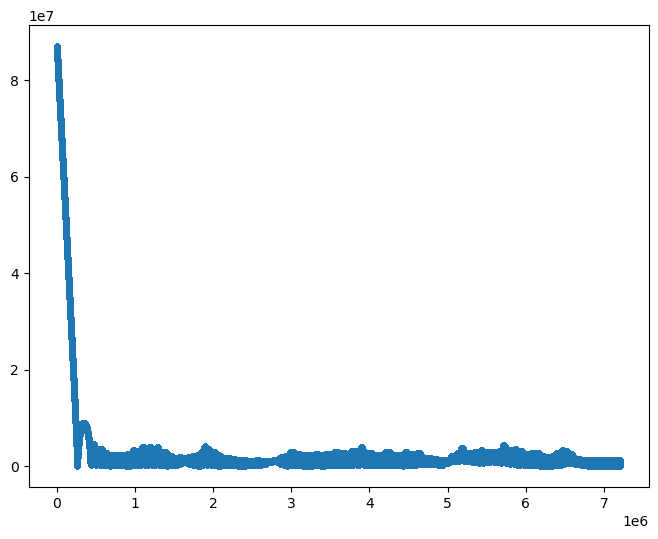

In [22]:
# plot the location in R-Theta for the first 1000 points, in polar coordinates (R, Theta), 

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(df_loaded["R_km"][1000:1000_1000], marker='o', linestyle='-', markersize=3)

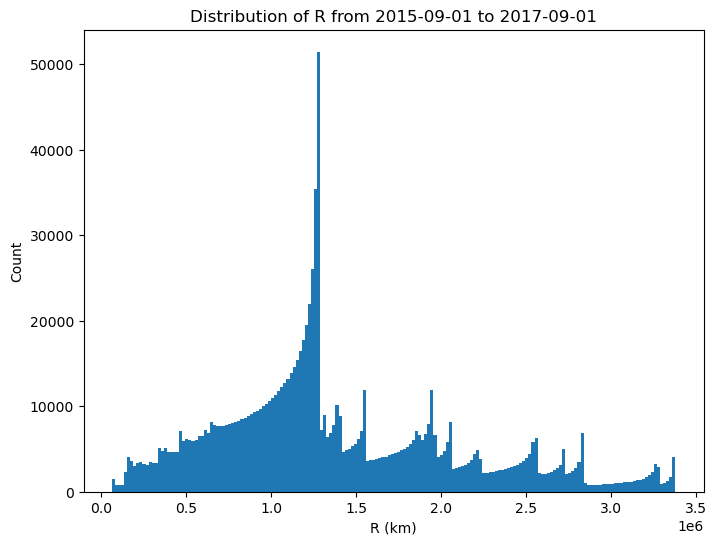

In [25]:
# plot a distribution of r from 2015-2017 Sep 1

start_utc = "2015-09-01T00:00:00"
stop_utc = "2017-09-01T00:00:00"

mask = (df_loaded["utc"] >= start_utc) & (df_loaded["utc"] < stop_utc)
r_values = df_loaded.loc[mask, "R_km"]

fig,ax=plt.subplots(figsize=(8,6))
ax.hist(r_values, bins='auto')
ax.set_xlabel("R (km)")
ax.set_ylabel("Count")
ax.set_title("Distribution of R from 2015-09-01 to 2017-09-01")
plt.show()

## J2000

In [17]:
cassini_location.attrs

{'target': 'CASSINI',
 'observer': 'SATURN',
 'frame': 'J2000',
 'abcorr': 'NONE',
 'step_seconds': 60,
 'start_utc': '2004-01-01T00:00:00',
 'stop_utc': '2017-09-15T10:40:00',
 'description': 'Cassini position and velocity relative to Saturn, expressed in J2000 Cartesian coordinates.'}

In [18]:
cassini_location

,utc,et,x_km,y_km,z_km,vx_km_s,vy_km_s,vz_km_s,r_km,speed_km_s,x_Rs,y_Rs,z_Rs,r_Rs
0,2004-01-01 00:00:00+00:00,1.261873e+08,-6.961639e+07,-5.068772e+07,-1.502691e+07,4.213407,3.071488,0.918440,8.741564e+07,5.294371,-1155.113603,-841.038679,-249.334826,1450.448673
1,2004-01-01 00:01:00+00:00,1.261873e+08,-6.961613e+07,-5.068753e+07,-1.502686e+07,4.213407,3.071488,0.918440,8.741532e+07,5.294371,-1155.109409,-841.035622,-249.333911,1450.443402
2,2004-01-01 00:02:00+00:00,1.261874e+08,-6.961588e+07,-5.068735e+07,-1.502680e+07,4.213407,3.071488,0.918440,8.741501e+07,5.294372,-1155.105214,-841.032564,-249.332997,1450.438131
3,2004-01-01 00:03:00+00:00,1.261874e+08,-6.961563e+07,-5.068717e+07,-1.502675e+07,4.213407,3.071488,0.918440,8.741469e+07,5.294372,-1155.101019,-841.029506,-249.332082,1450.432860
4,2004-01-01 00:04:00+00:00,1.261875e+08,-6.961538e+07,-5.068698e+07,-1.502669e+07,4.213408,3.071488,0.918440,8.741437e+07,5.294372,-1155.096825,-841.026448,-249.331168,1450.427589
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7209275,2017-09-15 10:35:00+00:00,5.587438e+08,1.756157e+04,5.802285e+04,-1.515090e+03,-17.499900,1.307190,-25.368109,6.064120e+04,30.846332,0.291391,0.962747,-0.025139,1.006192
7209276,2017-09-15 10:36:00+00:00,5.587438e+08,1.666681e+04,5.811902e+04,-2.516191e+03,-12.390155,1.949381,-8.288234,6.051392e+04,15.033657,0.276545,0.964343,-0.041750,1.004080
7209277,2017-09-15 10:37:00+00:00,5.587439e+08,1.599140e+04,5.824305e+04,-2.785418e+03,-10.575013,2.095546,-2.163249,6.046269e+04,10.995538,0.265338,0.966401,-0.046217,1.003230
7209278,2017-09-15 10:38:00+00:00,5.587439e+08,1.537299e+04,5.836566e+04,-2.857145e+03,-10.124144,1.978667,-0.512702,6.042385e+04,10.328421,0.255077,0.968435,-0.047407,1.002586


In [2]:
## load in the location data of cassini from "cassini_j2000_saturn_centered_2004_2017_60s.pkl"
# change the working directory to the current file's directory

os.chdir(Path("/Users/chengzhimao/Documents/Code/saturn2025"))

with open("cassini_j2000_saturn_centered_2004_2017_60s.pkl", "rb") as f:
    cassini_location = pickle.load(f)

In [3]:
cassini_location.head()

,utc,et,x_km,y_km,z_km,vx_km_s,vy_km_s,vz_km_s,r_km,speed_km_s,x_Rs,y_Rs,z_Rs,r_Rs
0,2004-01-01 00:00:00+00:00,1.261873e+08,-6.961639e+07,-5.068772e+07,-1.502691e+07,4.213407,3.071488,0.91844,8.741564e+07,5.294371,-1155.113603,-841.038679,-249.334826,1450.448673
1,2004-01-01 00:01:00+00:00,1.261873e+08,-6.961613e+07,-5.068753e+07,-1.502686e+07,4.213407,3.071488,0.91844,8.741532e+07,5.294371,-1155.109409,-841.035622,-249.333911,1450.443402
2,2004-01-01 00:02:00+00:00,1.261874e+08,-6.961588e+07,-5.068735e+07,-1.502680e+07,4.213407,3.071488,0.91844,8.741501e+07,5.294372,-1155.105214,-841.032564,-249.332997,1450.438131
3,2004-01-01 00:03:00+00:00,1.261874e+08,-6.961563e+07,-5.068717e+07,-1.502675e+07,4.213407,3.071488,0.91844,8.741469e+07,5.294372,-1155.101019,-841.029506,-249.332082,1450.432860
4,2004-01-01 00:04:00+00:00,1.261875e+08,-6.961538e+07,-5.068698e+07,-1.502669e+07,4.213408,3.071488,0.91844,8.741437e+07,5.294372,-1155.096825,-841.026448,-249.331168,1450.427589


In [29]:
type(pd.to_datetime('2010-12-21 00:50:00'))

pandas._libs.tslibs.timestamps.Timestamp

## Trajectory Plot

### 2d

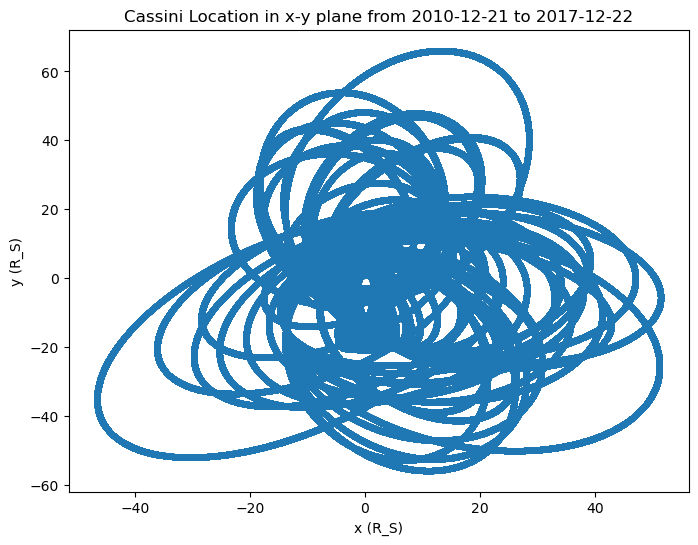

In [3]:
# plot the location in x-y plane for given time range 
start_utc = pd.to_datetime("2010-12-21 00:50:00", utc=True)
end_utc  = pd.to_datetime("2017-12-22 02:00:00", utc=True)

#select the data in the given time range
mask = (cassini_location['utc'] >= start_utc) & (cassini_location['utc'] <= end_utc)
cassini_subset = cassini_location.loc[mask]

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(cassini_subset['x_Rs'], cassini_subset['y_Rs'], marker='o', linestyle='-', markersize=3)
ax.set_xlabel("x (R_S)")
ax.set_ylabel("y (R_S)")
ax.set_title("Cassini Location in x-y plane from 2010-12-21 to 2017-12-22")
plt.show()

In [13]:
len(cassini_location)

7209280

In [ ]:
# plot the location in x-y plane for given time range with given point number
start_utc = pd.to_datetime("2010-12-21 00:50:00", utc=True)
end_utc  = pd.to_datetime("2017-12-22 02:00:00", utc=True)
n_points = 1000

#select the data in the given time range
mask = (cassini_location['utc'] >= start_utc) & (cassini_location['utc'] <= end_utc)
cassini_subset = cassini_location.loc[mask]

# select n_points evenly spaced points from cassini_subset
cassini_subset = cassini_subset.iloc[::len(cassini_subset) // n_points]

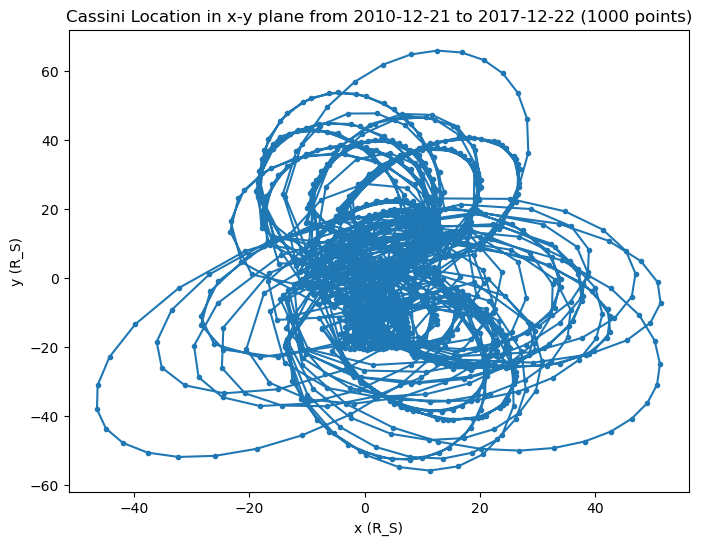

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(cassini_subset['x_Rs'], cassini_subset['y_Rs'], marker='o', linestyle='-', markersize=3)
ax.set_xlabel("x (R_S)")
ax.set_ylabel("y (R_S)")
ax.set_title("Cassini Location in x-y plane from 2010-12-21 to 2017-12-22 (1000 points)")
plt.show()

### 3d

In [ ]:
# using matplotlib to plot the location in 3d space for given time range with given point number
from mpl_toolkits.mplot3d import Axes3D
start_utc = pd.to_datetime("2010-12-21 00:50:00", utc=True)
end_utc  = pd.to_datetime("2017-12-22 02:00:00", utc=True)
n_points = 1000 


#select the data in the given time range
mask = (cassini_location['utc'] >= start_utc) & (cassini_location['utc'] <= end_utc)
cassini_subset = cassini_location.loc[mask] 

# select n_points evenly spaced points from cassini_subset
cassini_subset = cassini_subset.iloc[::len(cassini_subset) // n_points]

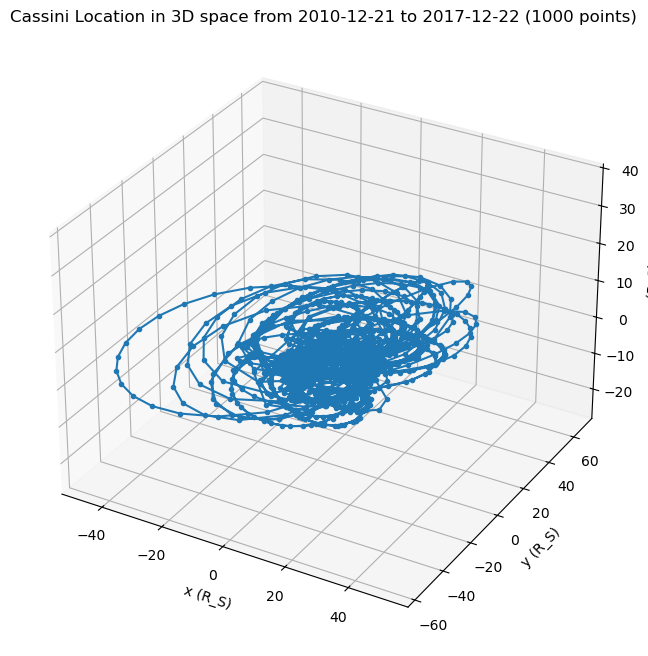

In [ ]:
# using matplotlib 
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(cassini_subset['x_Rs'], cassini_subset['y_Rs'], cassini_subset['z_Rs'], marker='o', linestyle='-', markersize=3)

ax.set_xlabel("x (R_S)")
ax.set_ylabel("y (R_S)")
ax.set_zlabel("z (R_S)")
ax.set_title("Cassini Location in 3D space from 2010-12-21 to 2017-12-22 (1000 points)")
plt.show()

In [ ]:
# using plotly to plot 3d location in space for given time range with given point number

In [ ]:

# using lines no markers
# colorbar means time from early to late

fig=go.Figure(data=[go.Scatter3d(
    x=cassini_subset['x_Rs'],
    y=cassini_subset['y_Rs'],
    z=cassini_subset['z_Rs'],
    mode='lines',
    line=dict(color='blue', width=2)
)]) 

fig.update_layout(
    title="Cassini Location in 3D space from 2010-12-21 to 2017-12-22 (1000 points)",
    scene=dict(
        xaxis_title='x (R_S)',
        yaxis_title='y (R_S)',
        zaxis_title='z (R_S)'
    )
)

In [20]:
start_utc = pd.to_datetime("2004-12-21 00:50:00", utc=True)
end_utc  = pd.to_datetime("2017-12-22 02:00:00", utc=True)
n_points = 5000

# Select data in time range
mask = (cassini_location['utc'] >= start_utc) & (cassini_location['utc'] <= end_utc)
cassini_subset = cassini_location.loc[mask].copy()

# Select approximately n_points evenly spaced rows
cassini_subset = cassini_subset.iloc[::len(cassini_subset) // n_points]
# idx = np.linspace(0, len(cassini_subset) - 1, n_points).astype(int)
# cassini_subset = cassini_subset.iloc[idx].copy()

In [22]:
# Convert UTC time to numeric values for coloring
time_numeric = cassini_subset['utc'].astype("int64") / 1e9  # seconds since epoch

fig = go.Figure(data=[go.Scatter3d(
    x=cassini_subset['x_Rs'],
    y=cassini_subset['y_Rs'],
    z=cassini_subset['z_Rs'],
    mode='lines',
    line=dict(
        color=time_numeric,
        colorscale='Viridis',
        width=3,
        colorbar=dict(
            title='UTC time',
            tickvals=[
                time_numeric.iloc[0],
                time_numeric.iloc[len(time_numeric)//2],
                time_numeric.iloc[-1]
            ],
            ticktext=[
                cassini_subset['utc'].iloc[0].strftime('%Y-%m-%d'),
                cassini_subset['utc'].iloc[len(cassini_subset)//2].strftime('%Y-%m-%d'),
                cassini_subset['utc'].iloc[-1].strftime('%Y-%m-%d')
            ]
        )
    )
)])

fig.update_layout(
    title=f"Cassini Location in 3D space from {start_utc.date()} to {end_utc.date()} ({n_points} points)",
    width=1200,
    height=800,
    scene=dict(
        xaxis_title='x (R_S)',
        yaxis_title='y (R_S)',
        zaxis_title='z (R_S)'
    ),
)

fig.show()